# Declared complementarity: contact without choosing a formulation

A string hangs between two supports and sags onto a curved floor. Where it
touches, the floor pushes back; where it does not, the floor exerts nothing.
That either-or is a **complementarity condition** — contact force
$\lambda_i \ge 0$, gap $u_i - \psi_i \ge 0$, and at least one of them zero:

$$0 \le \lambda_i \;\perp\; u_i - \psi_i \ge 0 .$$

Put a design question on top — *what tension makes the floor carry 30% of the
load?* — and the model is a mathematical program with complementarity
constraints (MPCC). Every feasible point violates the constraint
qualifications an interior-point method relies on, so how the condition is
*written* decides whether a solver finds the answer.

This notebook measures that, then shows the alternative: hand POUNCE the
pairs as data (`complementarity=[(row, var), ...]`) and let it choose.

* Written by hand as $\lambda_i(u_i-\psi_i)=0$, the solve reports
  **`Solve_Succeeded` at the same wrong tension for every target** — 1.3% of
  the load on the floor whether you asked for 10%, 30% or 60%.
* Declared, every target is met, and each answer carries a stationarity
  certificate.
* What it costs, how to pay for only one formulation
  (`complementarity_strategy`), what the certificate classes mean, and the
  one way the certificate can still be fooled.

Reference: the book page *Complementarity Constraints (MPCC)*
(`docs/src/complementarity.md`).

The `complementarity=` argument and `complementarity_strategy` are new in the
release after 0.14.0; the outputs below were produced at the commit the first
cell prints.

In [1]:
import os
os.environ["RUST_LOG"] = "error"   # the solver's INFO trace is not what this notebook is about
import platform, subprocess, time
import importlib.metadata as meta
import numpy as np
import matplotlib.pyplot as plt
import pounce

SOURCE_COMMIT = subprocess.run(
    ["git", "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print(f"python        {platform.python_version()}")
print(f"pounce-solver {meta.version('pounce-solver')}")
print(f"commit        {SOURCE_COMMIT[:12]}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})

python        3.13.17
pounce-solver 0.14.0
commit        6f2994539ed1


## 1. The model

$N = 40$ interior nodes at spacing $h = 1/41$, displacement $u$ (positive
up), a uniform load $w = 1$ per unit length, tension $T$, and a floor
$\psi(x) = -0.10 + 0.30\,(x - \tfrac12)^2$ that sits below both supports. With
$K = \mathrm{tridiag}(-1, 2, -1)/h^2$ the discrete equilibrium is

$$T\,K u + w - \lambda = 0, \qquad 0 \le \lambda_i \perp u_i - \psi_i \ge 0 ,$$

and the design problem picks $T$ so the floor carries a target share $R$ of the
load:

$$\min_{u,\lambda,T}\ \Big(h\sum_i \lambda_i - R\Big)^2 + 10^{-6}(T-1)^2 .$$

The floor force $F(T) = h\sum\lambda_i$ is zero until the string touches and
grows as $T$ falls — a kink exactly where the complementarity switches.

In POUNCE's terms a pair is `(row, var)`: constraint row $g_r$ (here the gap
row $u_i \ge \psi_i$) paired with variable $x_v$ (here $\lambda_i \ge 0$),
each measured from its one finite bound. The equilibrium rows are multiplied
by $h^2$ so every Jacobian entry is $O(1)$ — section 7 shows why that matters.
The `handwritten=True` variant appends the products $\lambda_i(u_i-\psi_i)=0$
as ordinary equality rows instead, the way the model would be written for a
plain NLP solver.

In [2]:
INF = 2e19
N = 40
h = 1.0 / (N + 1)
xs = np.arange(1, N + 1) * h
W = 1.0
PSI = -0.10 + 0.30 * (xs - 0.5) ** 2

class String:
    # z = (u, lam, T); rows: equilibrium (N), gap u >= psi (N), [products (N)]
    def __init__(self, R, reg=1e-6, scaled=True, handwritten=False):
        self.R, self.reg, self.hw = R, reg, handwritten
        self.s = h * h if scaled else 1.0
        self.K = (np.diag(np.full(N, 2.0)) - np.diag(np.ones(N - 1), 1)
                  - np.diag(np.ones(N - 1), -1)) / (h * h)
        r, c = [], []
        for i in range(N):
            for j in (i - 1, i, i + 1):
                if 0 <= j < N: r.append(i); c.append(j)
            r += [i, i]; c += [N + i, 2 * N]
        for i in range(N): r.append(N + i); c.append(i)
        if handwritten:
            for i in range(N): r += [2 * N + i] * 2; c += [i, N + i]
        self.jr, self.jc = np.array(r), np.array(c)
        hr, hc = [2 * N] * N, list(range(N))
        for a in range(N):
            for b in range(a + 1): hr.append(N + a); hc.append(N + b)
        if handwritten:
            for i in range(N): hr.append(N + i); hc.append(i)
        hr.append(2 * N); hc.append(2 * N)
        self.hr, self.hc = np.array(hr), np.array(hc)

    def split(self, z): return z[:N], z[N:2 * N], z[2 * N]
    def force(self, z): return h * self.split(z)[1].sum()

    def objective(self, z):
        return (self.force(z) - self.R) ** 2 + self.reg * (z[2 * N] - 1) ** 2
    def gradient(self, z):
        g = np.zeros(2 * N + 1)
        g[N:2 * N] = 2 * h * (self.force(z) - self.R)
        g[2 * N] = 2 * self.reg * (z[2 * N] - 1)
        return g
    def constraints(self, z):
        u, l, T = self.split(z)
        out = [self.s * (T * self.K @ u + W - l), u]
        if self.hw: out.append(l * (u - PSI))
        return np.concatenate(out)
    def jacobianstructure(self): return self.jr, self.jc
    def jacobian(self, z):
        u, l, T = self.split(z); Ku = self.K @ u; v = []
        for i in range(N):
            for j in (i - 1, i, i + 1):
                if 0 <= j < N: v.append(self.s * T * self.K[i, j])
            v += [-self.s, self.s * Ku[i]]
        v += [1.0] * N
        if self.hw:
            for i in range(N): v += [l[i], u[i] - PSI[i]]
        return np.array(v)
    def hessianstructure(self): return self.hr, self.hc
    def hessian(self, z, lag, of):
        out = [self.s * (self.K.T @ lag[:N]), [2 * of * h * h] * (N * (N + 1) // 2)]
        if self.hw: out.append(lag[2 * N:3 * N])
        out.append([2 * of * self.reg])
        return np.concatenate(out)

def string_problem(R, declare=True, scaled=True, handwritten=False, **options):
    m = String(R, scaled=scaled, handwritten=handwritten)
    rows = 3 * N if handwritten else 2 * N
    lb = np.concatenate([np.full(N, -INF), np.zeros(N), [0.05]])
    ub = np.concatenate([np.full(N, INF), np.full(N, INF), [50.0]])
    cl = np.concatenate([np.zeros(N), PSI] + ([np.zeros(N)] if handwritten else []))
    cu = np.concatenate([np.zeros(N), np.full(N, INF)] + ([np.zeros(N)] if handwritten else []))
    pairs = [(N + i, N + i) for i in range(N)] if declare else []
    p = pounce.Problem(n=2 * N + 1, m=rows, problem_obj=m, lb=lb, ub=ub,
                       cl=cl, cu=cu, complementarity=pairs)
    p.add_option("print_level", 0)
    for k, v in options.items():
        p.add_option(k, v)
    return p, m

Z0 = np.concatenate([np.zeros(N), np.zeros(N), [1.0]])   # flat string, no force, T = 1

def contact_nodes(m, z, tol=1e-6):
    u, _, _ = m.split(z)
    return int((u - PSI <= tol).sum())

## 2. Writing the product yourself

Three targets, the product rows appended, no pairs declared. The solver sees
an ordinary NLP.

In [3]:
TARGETS = [0.1, 0.3, 0.6]
print(f"{'R':>5} {'status':<26} {'T':>8} {'F = h*sum(lam)':>15} {'contact':>8} {'iters':>6}")
for R in TARGETS:
    p, m = string_problem(R, declare=False, handwritten=True)
    z, info = p.solve(Z0)
    print(f"{R:>5} {info['status_msg']:<26} {m.split(z)[2]:>8.4f} {m.force(z):>15.4f} "
          f"{contact_nodes(m, z):>8} {info['iter_count']:>6}")

    R status                            T  F = h*sum(lam)  contact  iters
  0.1 Solve_Succeeded              1.2178          0.0131        4     21


  0.3 Solve_Succeeded              1.2178          0.0131        4     26


  0.6 Solve_Succeeded              1.2178          0.0131        4     28


**Every target returns `Solve_Succeeded` at the same tension, with the floor
carrying 1.3% of the load.** The products are satisfied to machine precision
— the point is feasible — and it satisfies the KKT conditions of the NLP as
written, but the objective is nowhere near its minimum: lowering $T$ would
push more string onto the floor and move $F$ toward every one of those
targets. With the products written as equality rows, the reformulated NLP has
stationary points that are not minimizers of the complementarity problem, and
an ordinary solve has no way to tell them apart. This is the failure the
declared route is built to catch, and it is silent: the status is the best one
there is.

## 3. Declaring the pairs

Same model, no product rows, the pairs passed as data. Nothing else is set.

In [4]:
results = {}
print(f"{'R':>5} {'status':<26} {'T':>8} {'F':>8} {'contact':>8} {'class':>6} {'answered by':<24} {'iters':>6}")
for R in TARGETS:
    p, m = string_problem(R)
    t0 = time.perf_counter()
    z, info = p.solve(Z0)
    wall = time.perf_counter() - t0
    cc = info["complementarity"]
    results[R] = (m, z, info, wall)
    print(f"{R:>5} {info['status_msg']:<26} {m.split(z)[2]:>8.4f} {m.force(z):>8.4f} "
          f"{contact_nodes(m, z):>8} {cc['certificate']['class']:>6} {cc['accepted_by']:<24} "
          f"{cc['total_iterations']:>6}")

    R status                            T        F  contact  class answered by               iters


  0.1 Solved_To_Acceptable_Level   1.0329   0.1000       12      S Scholtes continuation       209


  0.3 Solve_Succeeded              0.6925   0.3000       22      S Scholtes continuation       179


  0.6 Solve_Succeeded              0.2971   0.6000       30      S Scholtes continuation       214


Every target is met, at a different tension, with a different contact region.
(R = 0.1 reports `Solved_To_Acceptable_Level`: that is the convergence level
of the solve that produced the answer; its certificate is still `S`.)
`info["complementarity"]` says how the answer was reached and what it is:

In [5]:
m, z, info, wall = results[0.3]
cc = info["complementarity"]
print(cc["summary"])
print()
for stage, tau, status, iters, max_prod in cc["solves"]:
    tau_s = "exact" if tau is None else f"{tau:.0e}"
    print(f"  {stage:<22} tau={tau_s:<6} {status:<26} {iters:>4} iters  max|G*H| = {max_prod:.1e}")
print()
print({k: v for k, v in cc["certificate"].items()})

pounce: complementarity: answered by the Scholtes continuation formulation (11 lowered solves, 179 iterations in all, max |G·H| = 1.1e-37); 40 pairs, 0 biactive; stationarity: S (strongly stationary).

  Scholtes continuation  tau=1e+00  SolveSucceeded               19 iters  max|G*H| = 1.1e-02
  Scholtes continuation  tau=1e-01  SolveSucceeded                4 iters  max|G*H| = 1.1e-02
  Scholtes continuation  tau=1e-02  SolveSucceeded                3 iters  max|G*H| = 5.8e-03
  Scholtes continuation  tau=1e-03  SolveSucceeded                9 iters  max|G*H| = 1.0e-03
  Scholtes continuation  tau=1e-04  SolveSucceeded               13 iters  max|G*H| = 1.0e-04
  Scholtes continuation  tau=1e-05  SolveSucceeded                9 iters  max|G*H| = 1.0e-05
  Scholtes continuation  tau=1e-06  SolveSucceeded                8 iters  max|G*H| = 1.0e-06
  Scholtes continuation  tau=1e-07  SolveSucceeded                6 iters  max|G*H| = 1.0e-07
  Scholtes continuation  tau=1e-08  SolveSucce

The driver ran the **Scholtes continuation** (relax every product to
$G\cdot H \le \tau$, drive $\tau$ from 1 to $10^{-8}$, each solve warm-started from
the last, then finish with the exact product) and then the **exact product**
from your start, and kept the strongly stationary answer with the lower
objective. The certificate is computed from the model's own derivatives at the
returned point, independently of the solve that produced it:

| `class` | meaning |
|---|---|
| `S` | strongly stationary: a local-minimum candidate in the usual sense |
| `W` | weakly stationary only — some biactive pair admits a descent direction that switches which side is zero |
| `none` | not stationary at all; the point is reported at `Solved_To_Acceptable_Level`, never as success |
| `not_searched` | not determined (the multipliers form a set too large to search); accepted like `S` |

`residual` against `resid_tol` is how close the call was — section 7 is about
why that number is worth reading.

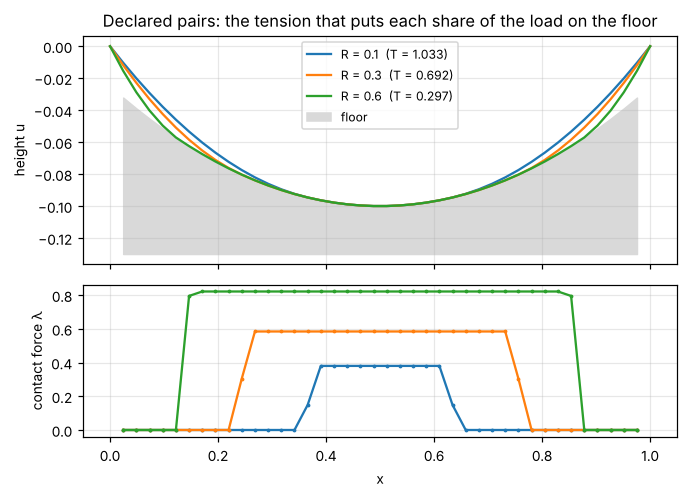

In [6]:
m, z, info, _ = results[0.3]
u, lam, T = m.split(z)
xfull = np.concatenate([[0], xs, [1]])
fig, (a1, a2) = plt.subplots(2, 1, figsize=(6.4, 4.6), sharex=True,
                             gridspec_kw={"height_ratios": [3, 2]})
for R, (mm, zz, _, _) in results.items():
    uu = mm.split(zz)[0]
    a1.plot(xfull, np.concatenate([[0], uu, [0]]), label=f"R = {R}  (T = {mm.split(zz)[2]:.3f})")
a1.fill_between(xs, PSI, PSI.min() - 0.03, color="0.85", label="floor")
a1.set_ylabel("height u"); a1.legend(fontsize=8, loc="upper center")
a1.set_title("Declared pairs: the tension that puts each share of the load on the floor")
for R, (mm, zz, _, _) in results.items():
    a2.plot(xs, mm.split(zz)[1], marker=".", ms=3, label=f"R = {R}")
a2.set_ylabel("contact force λ"); a2.set_xlabel("x")
plt.tight_layout(); plt.show()

## 4. A converged solve is not an answer on its status alone

The last row above is the exact product, run from your start: it ended at
`Solved_To_Acceptable_Level` and was not kept. Restricting the driver to that
formulation (`complementarity_strategy=exact`, section 6) shows what happens
when it is the only one allowed — the same lowering section 2 wrote by hand,
run with the driver's defaults for declared pairs (`bound_relax_factor=0`,
`honor_original_bounds=yes`):

In [7]:
p, m = string_problem(0.3, complementarity_strategy="exact")
z, info = p.solve(Z0)
cc = info["complementarity"]
for stage, tau, status, iters, max_prod in cc["solves"]:
    print(f"  {stage:<16} {status:<26} {iters:>4} iters")
print(cc["summary"])
print(f"T = {m.split(z)[2]:.4f}, F = {m.force(z):.4f}")

  exact product    SolvedToAcceptableLevel      97 iters
  l1 penalty       SolveSucceeded               30 iters
pounce: complementarity: answered by the l1 penalty formulation (2 lowered solves, 127 iterations in all, max |G·H| = 6.3e-9); 40 pairs, 0 biactive; stationarity: S (strongly stationary).
T = 0.6925, F = 0.3000


The exact-product solve's point does not certify as stationary, so the driver
does not stop there: it falls back to the ℓ₁ penalty formulation, which reaches
the target. A stage *answers* only if it converged, every product is within
`constr_viol_tol`, **and** the point certifies `S`.

## 5. The design curve

Sweeping the target traces $T^\star(R)$ and the contact region. Below the
lift-off tension the floor carries nothing; the kink there is the
complementarity switching, and it is where a smooth reformulation has the
hardest time.

14 solves, 13.3 s, all certified S; max |F - R| = 8.4e-07


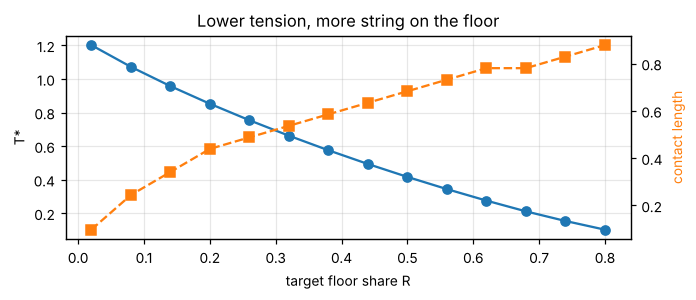

In [8]:
sweep = np.linspace(0.02, 0.8, 14)
Ts, Fs, contact, iters = [], [], [], []
t0 = time.perf_counter()
for R in sweep:
    p, m = string_problem(R)
    z, info = p.solve(Z0)
    assert info["complementarity"]["certificate"]["class"] == "S", (R, info["status_msg"])
    Ts.append(m.split(z)[2]); Fs.append(m.force(z)); contact.append(contact_nodes(m, z) * h)
    iters.append(info["complementarity"]["total_iterations"])
print(f"{len(sweep)} solves, {time.perf_counter() - t0:.1f} s, all certified S; "
      f"max |F - R| = {np.max(np.abs(np.array(Fs) - sweep)):.1e}")
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.plot(sweep, Ts, "o-", label="tension T*")
ax.set_xlabel("target floor share R"); ax.set_ylabel("T*")
ax2 = ax.twinx(); ax2.plot(sweep, contact, "s--", color="C1", label="contact length")
ax2.set_ylabel("contact length", color="C1"); ax2.grid(False)
ax.set_title("Lower tension, more string on the floor")
plt.tight_layout(); plt.show()

## 6. What it costs, and `complementarity_strategy`

Running two formulations costs roughly the iterations of both. On nonconvex
MPCCs each one reaches local minima the other avoids — on the MPCC benchmark
corpus the exact product alone reaches the optimum on 48 of 60 cells and the
continuation on 60, while on the CALIPSO bunny-hop the continuation alone
settles 2.4× worse on 3 of 5 starts — so running both is the default. When you
know which works for your model, `complementarity_strategy` runs only it:

In [9]:
print(f"{'R':>5} {'strategy':<13} {'status':<26} {'F':>7} {'class':>6} {'answered by':<24} {'iters':>6} {'wall':>6}")
for R in TARGETS:
    for strategy in ["both", "exact", "continuation"]:
        p, m = string_problem(R, complementarity_strategy=strategy)
        t0 = time.perf_counter(); z, info = p.solve(Z0); wall = time.perf_counter() - t0
        cc = info["complementarity"]
        print(f"{R:>5} {strategy:<13} {info['status_msg']:<26} {m.force(z):>7.4f} "
              f"{cc['certificate']['class']:>6} {cc['accepted_by']:<24} "
              f"{cc['total_iterations']:>6} {wall:>5.2f}s")

    R strategy      status                           F  class answered by               iters   wall


  0.1 both          Solved_To_Acceptable_Level  0.1000      S Scholtes continuation       209  1.01s


  0.1 exact         Solved_To_Acceptable_Level  0.0000      S exact product               111  0.45s


  0.1 continuation  Solved_To_Acceptable_Level  0.1000      S Scholtes continuation        98  0.39s


  0.3 both          Solve_Succeeded             0.3000      S Scholtes continuation       179  0.66s


  0.3 exact         Solve_Succeeded             0.3000      S l1 penalty                  127  0.35s


  0.3 continuation  Solve_Succeeded             0.3000      S Scholtes continuation        82  0.42s


  0.6 both          Solve_Succeeded             0.6000      S Scholtes continuation       214  0.58s


  0.6 exact         Solve_Succeeded             0.6000      S l1 penalty                  132  0.32s


  0.6 continuation  Solve_Succeeded             0.6000      S Scholtes continuation       105  0.43s


On this model the continuation alone reaches every target at about half the
iterations of `both`. The exact product alone is the instructive row: at
R = 0.3 and 0.6 its point does not certify and the penalty answers, but at
R = 0.1 it **answers itself with `S` at F = 0** — the string held clear of the
floor. That certificate is not wrong: above the lift-off tension the floor
force is identically zero, so the objective is flat in $T$ and the point is
genuinely stationary. It is a plateau, not the design. `S` is a local
statement; the default runs both formulations and keeps the lower objective
precisely because a single route can stop on one. Which route wins is
model-dependent. The ℓ₁ penalty runs under every setting when nothing else
answers, and the verdict reported when nothing answers at all is always an
exact-product solve's, never a relaxed one's success.

## 7. When the certificate is fooled: scaling

The certificate's tolerance is relative to the largest entry of its
stationarity system. Drop the $h^2$ row scaling and the equilibrium rows carry
entries of order $2T/h^2 \approx 4\cdot10^3$, while the objective's gradient is
of order $10^{-3}$:

In [10]:
p, m = string_problem(0.1, scaled=False, complementarity_strategy="exact")
z, info = p.solve(Z0)
cert = info["complementarity"]["certificate"]
print(f"{info['status_msg']}: T = {m.split(z)[2]:.4f}, F = {m.force(z):.4f} (target 0.1)")
print(f"class {cert['class']}, tight {cert['tight']}, residual {cert['residual']:.3e} "
      f"(band {cert['resid_tol']:.3e})")

Solve_Succeeded: T = 1.1824, F = 0.0283 (target 0.1)
class S, tight True, residual 3.943e-03 (band 4.015e-01)


A point that misses the target by a factor of 3.5 is reported `S`, and even
`tight`. It is not a defect of the declared route — the interior-point
method's own convergence test accepts the same point for the same reason —
and nothing in the certificate gives it away. Its tolerances are relative to
the largest entry of the stationarity system, so on a badly scaled model they
are as loose as the scale is bad. The defense is the model's scaling: here,
multiplying the equilibrium rows by $h^2$, after which every route finds the
target (sections 3 and 6). A certificate is evidence about the model you
wrote, at the scale you wrote it.

## 8. A weakly stationary point

Ralph's classic example, $\min 2x - y$ subject to $0 \le y \perp y - x \ge 0$,
$x \ge 0$, has its answer at the origin — where **no** multiplier has the right
sign on the biactive pair. The driver reports the point, but as a fallback,
not an answer:

In [11]:
class Ralph1:
    def objective(self, z): return 2 * z[0] - z[1]
    def gradient(self, z): return np.array([2.0, -1.0])
    def constraints(self, z): return np.array([z[1] - z[0]])
    def jacobianstructure(self): return np.array([0, 0]), np.array([0, 1])
    def jacobian(self, z): return np.array([-1.0, 1.0])
    def hessianstructure(self): return np.array([], dtype=int), np.array([], dtype=int)
    def hessian(self, z, lagrange, obj_factor): return np.array([])

p = pounce.Problem(n=2, m=1, problem_obj=Ralph1(), lb=[0.0, 0.0], ub=[INF, INF],
                   cl=[0.0], cu=[INF], complementarity=[(0, 1)])
p.add_option("print_level", 0)
x, info = p.solve(np.array([1.0, 2.0]))
cc = info["complementarity"]
print(f"x = {np.round(x, 6)}, status {info['status_msg']}")
print(f"class {cc['certificate']['class']}, accepted_by {cc['accepted_by']}, fallback {cc['fallback']}")

x = [0. 0.], status Solve_Succeeded
class W, accepted_by None, fallback Scholtes continuation


`accepted_by` is `None` and `fallback` names the stage: no formulation found a
strongly stationary point, and the weakly stationary one is what is left. Here
the origin happens to be the minimizer; in general a `W` point is where to try
other starts.

## 9. From Pyomo

`pyomo.mpec` components need no transformation: `SolverFactory("pounce")`
writes them as complementarity rows of the `.nl` file and the same driver runs.

In [12]:
try:
    import pyomo.environ as pyo
    from pyomo.mpec import Complementarity, complements
    import pyomo_pounce  # noqa: F401  (registers the "pounce" solver)
except ImportError as e:
    print("Pyomo / pyomo-pounce not installed:", e)
else:
    mdl = pyo.ConcreteModel()
    mdl.x = pyo.Var(bounds=(0, 2)); mdl.y1 = pyo.Var(); mdl.y2 = pyo.Var()
    mdl.obj = pyo.Objective(expr=(mdl.x - 1) ** 2 + (mdl.y1 - 1) ** 2 + mdl.y2 ** 2)
    mdl.c1 = Complementarity(expr=complements(mdl.y1 >= 0, 2 * mdl.y1 - 1 - mdl.x >= 0))
    mdl.c2 = Complementarity(expr=complements(mdl.y2 >= 0, mdl.x + 2 * mdl.y2 - 1 >= 0))
    res = pyo.SolverFactory("pounce").solve(mdl)
    print(res.solver.termination_condition,
          [round(pyo.value(v), 6) for v in (mdl.x, mdl.y1, mdl.y2)])

optimal [1.0, 1.0, 0.0]


With `tee=True` the solver's console shows the same summary line as
`info["complementarity"]["summary"]`, certificate included.

## 10. Limits

* **Pair shapes**: a pair is one-sided (a row with one finite side; a second
  bound on its variable is kept as an ordinary limit) or mixed (`l <= x <= u ⟂ g`
  with the row free: g >= 0 at l, g <= 0 at u, g = 0 between). A boxed row is
  refused with the reason.
* **Cones are not supported**: friction-cone complementarity has to be written
  as scalar pairs.
* **Entry points that would drop the pairs refuse them** rather than solve the
  model without them — `pounce.Solver`, `find_minima`, `solve_nlp_batch`,
  `solve_with_sens`, the CLI's `--minima` and sensitivity requests,
  `pounce verify`, `check-x0`. Presolve is declined.

In [13]:
p, m = string_problem(0.3)
try:
    pounce.Solver(p).solve(Z0)
except ValueError as e:
    print("ValueError:", e)

ValueError: Solver does not support declared complementarity pairs; use Problem.solve()


* **The JSON solve report does not carry the certificate yet**: read the
  console line or `info["complementarity"]`.
* **The certificate is local evidence, not a global one.** `S` says no
  first-order descent direction exists at the point; on a nonconvex model a
  better local minimum may still exist elsewhere — section 6's plateau is an
  `S` point with the floor carrying nothing.